# EDA 3: Price, Growth, Liquidity and Value

EDA 2 looked at **what is listed and what people follow** (listing counts, followers, popularity).
EDA 3 moves to the **investment question**: where and when did prices grow, what drives price,
how easily do properties sell, and which segments look undervalued.

It reads the output of `featureengineering.py`, so run that script first.

| Section | Question | Feeds story chapter |
|---|---|---|
| 0 | Is the data trustworthy, and which years can we use? | Framing |
| 1 | Where are prices highest? | Where |
| 2 | When did prices rise, and is there seasonality? | When |
| 3 | Which districts grew fastest? | Where / Strategy |
| 4 | What property features drive price? | What |
| 5 | How liquid is each segment? | Liquidity |
| 6 | Which segments sell below their district norm? | Undervaluation |
| 7 | Growth vs liquidity per district (quadrant preview) | Strategy |
| 8 | Community-level table for clustering | Creativity |

## Setup

In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)

# Locate the project root by walking up until data/processed is found,
# so this works whether the notebook sits in notebooks/ or the project root.
def find_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if (p / "data" / "processed").exists():
            return p
    raise FileNotFoundError("Could not find data/processed. Run featureengineering.py first.")

ROOT = find_root()
DATA_PATH = ROOT / "data" / "processed" / "BeijingHousingPrices_featured.csv"
df = pd.read_csv(DATA_PATH, parse_dates=["tradeTime"], low_memory=False)
print(df.shape)
df.head(3)

(318851, 52)


,url,id,Lng,Lat,Cid,tradeTime,DOM,followers,totalPrice,price,square,livingRoom,drawingRoom,kitchen,bathRoom,floor,buildingType,constructionTime,renovationCondition,buildingStructure,ladderRatio,elevator,fiveYearsProperty,subway,district,...,story,is_high_rise,district_name,district_zone,trade_year,trade_month,trade_quarter,year_month,building_age,age_bucket,is_new_build,total_rooms,area_per_room,size_category,price_per_sqm_calc,price_diff_pct,log_total_price,log_price_per_sqm,district_median_price,price_vs_district,followers_per_day,is_fast_sale,amenity_score,high_floor_with_elevator,distance_to_center_km
0,https://bj.lianjia.com/chengjiao/101084782030....,101084782030,116.475489,40.019520,1111027376244,2016-08-09,1464.0,106,415.0,31680,131.00,2.0,1.0,1,1,High 26,1.0,2005.0,3,6,0.217,1.0,0.0,1.0,7,...,26,1,Chaoyang,Inner suburb,2016,8,3,2016-08,11.0,6-15,0.0,5.0,65.50,90-140,31679.389313,0.000019,6.028279,10.363441,48575.0,0.652187,0.072404,0.0,2.0,1,14.000873
1,https://bj.lianjia.com/chengjiao/101086012217....,101086012217,116.453917,39.881534,1111027381879,2016-07-28,903.0,126,575.0,43436,132.38,2.0,2.0,1,2,High 22,1.0,2004.0,4,6,0.667,1.0,1.0,0.0,7,...,22,1,Chaoyang,Inner suburb,2016,7,3,2016-07,12.0,6-15,0.0,7.0,66.19,90-140,43435.564285,0.000010,6.354370,10.679044,48575.0,0.894205,0.139535,0.0,2.0,1,5.682395
2,https://bj.lianjia.com/chengjiao/101086041636....,101086041636,116.561978,39.877145,1111040862969,2016-12-11,1271.0,48,1030.0,52021,198.00,3.0,2.0,1,3,Middle 4,4.0,2005.0,3,6,0.500,1.0,0.0,0.0,7,...,4,0,Chaoyang,Inner suburb,2016,12,4,2016-12,11.0,6-15,0.0,9.0,66.00,140+,52020.202020,0.000015,6.937314,10.859403,48575.0,1.070942,0.037766,0.0,1.0,0,14.464253


In [4]:
# ---- Analysis settings: adjust after looking at Section 0 -----------------
WINDOW = (2010, 2017)     # first and last year used for trend / growth analysis
MIN_N = 30                # minimum transactions for a district-year (or community) to be trusted

# One colour per district, reused in every chart so readers can track them
DISTRICTS = sorted(df["district_name"].dropna().unique())
DISTRICT_COLORS = dict(zip(DISTRICTS, sns.color_palette("tab20", len(DISTRICTS))))
ZONE_ORDER = ["Core", "Inner suburb", "Outer"]
ZONE_COLORS = dict(zip(ZONE_ORDER, ["#1f4e79", "#2e86c1", "#85c1e9"]))

## 0. Data sanity checks

Before drawing conclusions, check the engineered columns and decide which years are reliable.

In [5]:
# Missing values in the columns we rely on in this notebook
key_cols = ["price", "totalPrice", "square", "trade_year", "DOM", "followers",
            "building_age", "story", "distance_to_center_km", "district_name"]
df[key_cols].isna().mean().mul(100).round(1).rename("% missing").to_frame()

,% missing
price,0.0
totalPrice,0.0
square,0.0
trade_year,0.0
DOM,49.5
followers,0.0
building_age,6.1
story,0.0
distance_to_center_km,0.0
district_name,0.0


In [6]:
# Does the given price equal totalPrice * 10,000 / square? (price_diff_pct should be near 0)
print(df["price_diff_pct"].describe().round(4))
print("Share of rows where the two prices differ by more than 5%:",
      round((df["price_diff_pct"].abs() > 0.05).mean() * 100, 2), "%")

count    318851.0000
mean         -0.0005
std           0.0207
min          -0.9850
25%           0.0000
50%           0.0000
75%           0.0000
max           0.0076
Name: price_diff_pct, dtype: float64
Share of rows where the two prices differ by more than 5%: 0.07 %


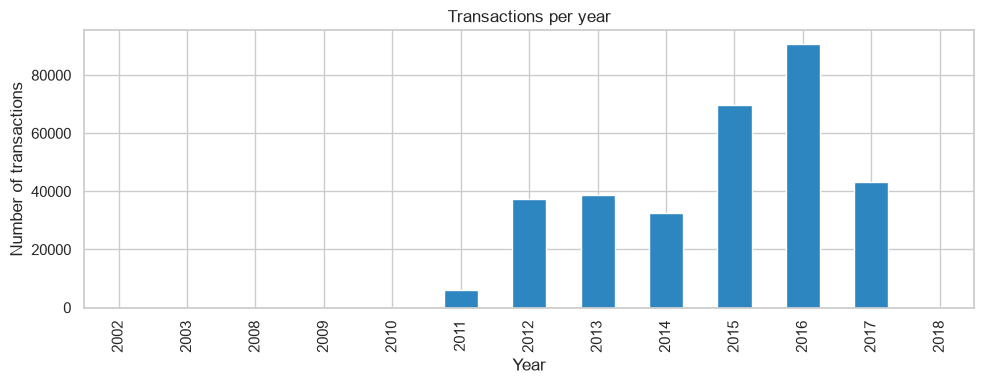

,n
trade_year,
2002,3
2003,1
2008,1
2009,1
2010,189
2011,6010
2012,37221
2013,38751
2014,32602


In [7]:
# Transactions per year: the dataset nominally spans 2002-2018, but early years may be thin
counts = df["trade_year"].value_counts().sort_index()
ax = counts.plot(kind="bar", figsize=(10, 4), color="#2e86c1")
ax.set_title("Transactions per year")
ax.set_xlabel("Year")
ax.set_ylabel("Number of transactions")
plt.tight_layout()
plt.show()
counts.to_frame("n")

**Decision point:** if the early years have only a handful of rows, any "growth since 2005" figure
would be noise. Pick `WINDOW` in the settings cell so every year in it has enough data, and note the
choice on your methodology slide.

In [8]:
# Work on the window from now on (kept as a separate frame so the full data stays available)
w = df[df["trade_year"].between(*WINDOW)].copy()
print(f"{len(w):,} of {len(df):,} rows fall inside {WINDOW[0]}-{WINDOW[1]}")

# Price outliers: look at the extremes before deciding anything
w["price"].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(0).to_frame()

318,624 of 318,851 rows fall inside 2010-2017


,price
count,318624.0
mean,43520.0
std,21705.0
min,1.0
1%,12829.0
5%,18056.0
50%,38726.0
95%,86618.0
99%,115379.0
max,156250.0


## 1. Where are prices highest?

EDA 2 showed which districts have the most listings. Volume is not value, so compare them with
**median price per sqm** (the median is robust to the outliers seen above).

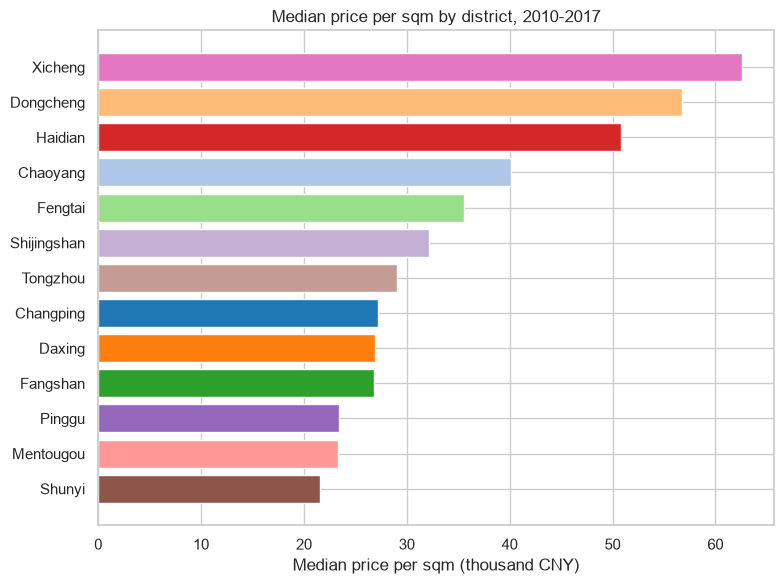

In [9]:
order = w.groupby("district_name")["price"].median().sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(order.index, order.values / 1000, color=[DISTRICT_COLORS[d] for d in order.index])
ax.set_title(f"Median price per sqm by district, {WINDOW[0]}-{WINDOW[1]}")
ax.set_xlabel("Median price per sqm (thousand CNY)")
plt.tight_layout()
plt.show()

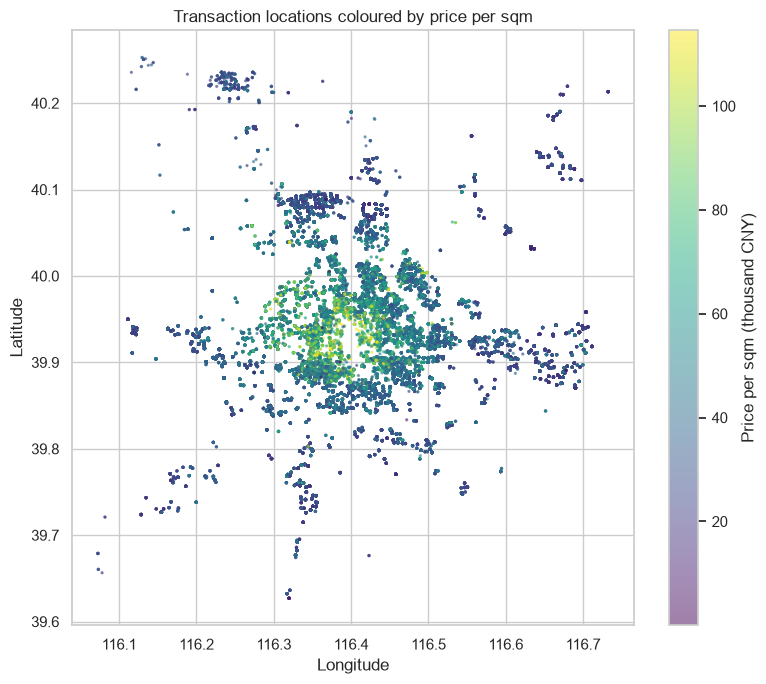

In [10]:
# Geographic view: each point is a transaction (sampled for speed), colour = price per sqm
sample = w.sample(min(60_000, len(w)), random_state=42)
sample = sample[sample["Lng"].between(115.4, 117.6) & sample["Lat"].between(39.4, 41.1)]

fig, ax = plt.subplots(figsize=(8, 7))
sc = ax.scatter(sample["Lng"], sample["Lat"], c=sample["price"].clip(upper=sample["price"].quantile(0.99)) / 1000,
                s=2, alpha=0.5, cmap="viridis")
ax.set_title("Transaction locations coloured by price per sqm")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
fig.colorbar(sc, label="Price per sqm (thousand CNY)")
plt.tight_layout()
plt.show()

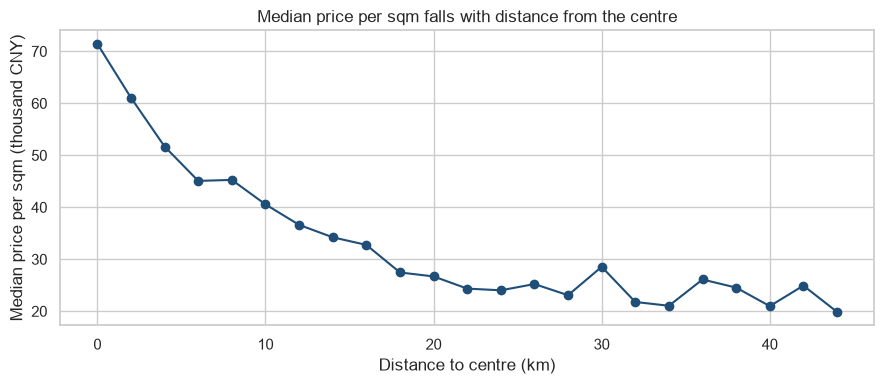

In [11]:
# Does distance to the centre explain the pattern? Median price by 2 km distance band
w["dist_band"] = pd.cut(w["distance_to_center_km"], bins=range(0, 62, 2), right=False)
band = w.groupby("dist_band", observed=True)["price"].agg(["median", "size"])
band = band[band["size"] >= MIN_N]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot([i.left for i in band.index], band["median"] / 1000, marker="o", color="#1f4e79")
ax.set_title("Median price per sqm falls with distance from the centre")
ax.set_xlabel("Distance to centre (km)")
ax.set_ylabel("Median price per sqm (thousand CNY)")
plt.tight_layout()
plt.show()

## 2. When did prices rise?

Look at the overall trend first, then split by zone, then check whether the month of sale matters.

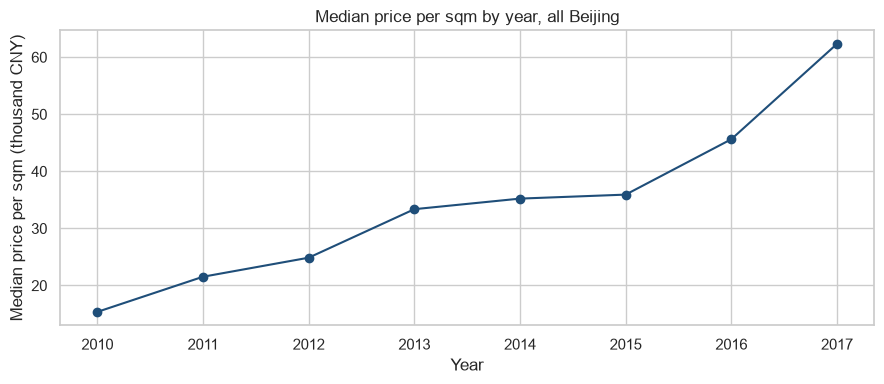

,YoY growth %
trade_year,
2010,NaN
2011,40.0
2012,15.5
2013,34.2
2014,5.6
2015,2.0
2016,27.0
2017,36.6


In [12]:
yearly = w.groupby("trade_year")["price"].median()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(yearly.index, yearly.values / 1000, marker="o", color="#1f4e79")
ax.set_title("Median price per sqm by year, all Beijing")
ax.set_xlabel("Year")
ax.set_ylabel("Median price per sqm (thousand CNY)")
plt.tight_layout()
plt.show()

yoy = yearly.pct_change().mul(100).round(1).rename("YoY growth %")
yoy.to_frame()

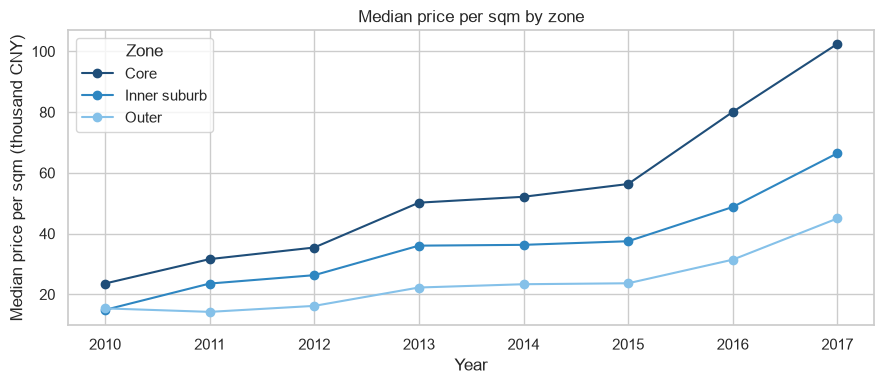

In [13]:
# Same trend split by zone (Core / Inner suburb / Outer)
zone_year = (w.groupby(["trade_year", "district_zone"])["price"].median()
               .unstack("district_zone")[ZONE_ORDER])

fig, ax = plt.subplots(figsize=(9, 4))
for z in ZONE_ORDER:
    ax.plot(zone_year.index, zone_year[z] / 1000, marker="o", label=z, color=ZONE_COLORS[z])
ax.set_title("Median price per sqm by zone")
ax.set_xlabel("Year")
ax.set_ylabel("Median price per sqm (thousand CNY)")
ax.legend(title="Zone")
plt.tight_layout()
plt.show()

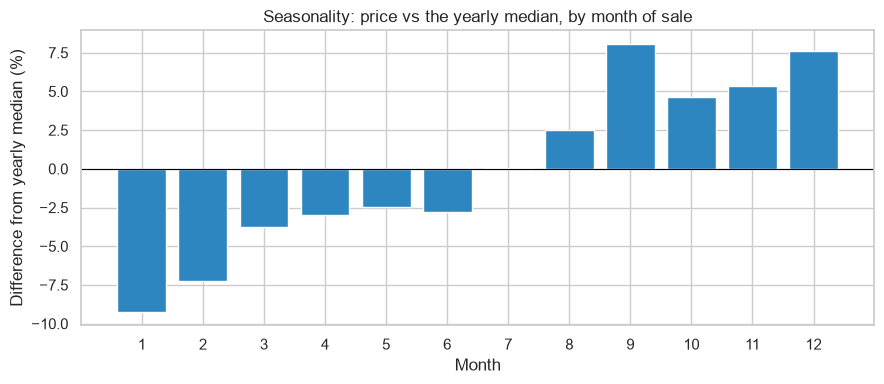

In [14]:
# Seasonality: price relative to that year's median, averaged by month of sale.
# Dividing by the yearly median removes the long-run trend so only the month effect remains.
w["price_idx"] = w["price"] / w.groupby("trade_year")["price"].transform("median")
season = w.groupby("trade_month")["price_idx"].median()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(season.index, (season.values - 1) * 100, color="#2e86c1")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(range(1, 13))
ax.set_title("Seasonality: price vs the yearly median, by month of sale")
ax.set_xlabel("Month")
ax.set_ylabel("Difference from yearly median (%)")
plt.tight_layout()
plt.show()

**Caution:** a month effect inside a year can be confused with the trend if prices rose quickly that year
(later months look pricier just because time passed). If the bars show a steady rise from January to
December, that is the trend, not seasonality.

## 3. Which districts grew fastest?

Compound annual growth rate (CAGR) of the median price per sqm between the first and last year of the window.
Districts with too few transactions in either end year are dropped, because a median of a few rows is noise.

Dropped for thin data in an end year: ['Changping', 'Chaoyang', 'Daxing', 'Dongcheng', 'Fangshan', 'Fengtai', 'Haidian', 'Pinggu', 'Shijingshan', 'Shunyi', 'Tongzhou', 'Xicheng']


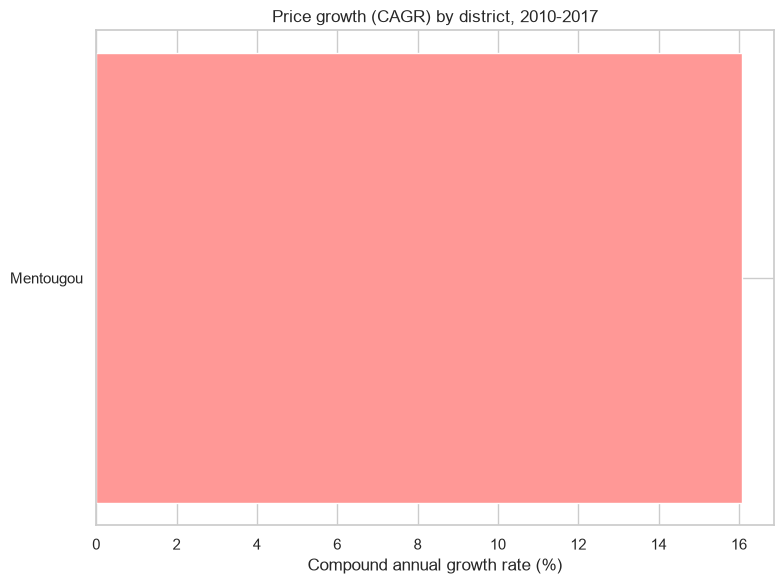

,p_start,p_end,n_start,n_end,cagr_pct
district_name,,,,,
Mentougou,15380.0,43650.0,187.0,267,16.1


In [15]:
dy = w.groupby(["district_name", "trade_year"])["price"].agg(median="median", n="size").reset_index()
start, end = WINDOW

s = dy[dy["trade_year"] == start].set_index("district_name")
e = dy[dy["trade_year"] == end].set_index("district_name")
growth = pd.DataFrame({"p_start": s["median"], "p_end": e["median"], "n_start": s["n"], "n_end": e["n"]}).dropna()
growth = growth[(growth["n_start"] >= MIN_N) & (growth["n_end"] >= MIN_N)]
growth["cagr_pct"] = ((growth["p_end"] / growth["p_start"]) ** (1 / (end - start)) - 1) * 100
growth = growth.sort_values("cagr_pct")

dropped = set(DISTRICTS) - set(growth.index)
if dropped:
    print("Dropped for thin data in an end year:", sorted(dropped))

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(growth.index, growth["cagr_pct"], color=[DISTRICT_COLORS[d] for d in growth.index])
ax.set_title(f"Price growth (CAGR) by district, {start}-{end}")
ax.set_xlabel("Compound annual growth rate (%)")
plt.tight_layout()
plt.show()
growth.round(1)

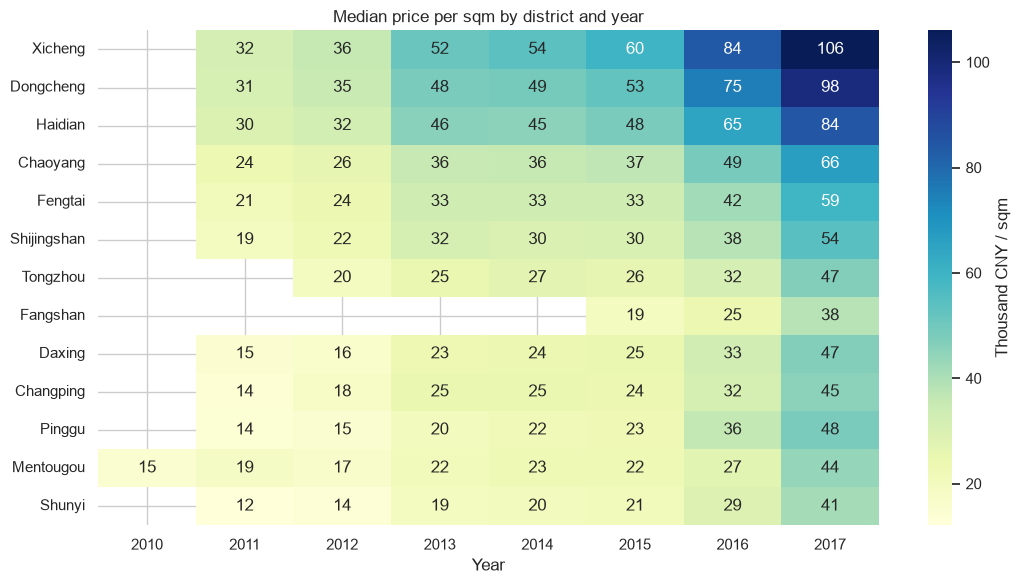

In [16]:
# Heatmap of median price per district and year (thousand CNY per sqm). Blank = fewer than MIN_N rows.
pivot = dy[dy["n"] >= MIN_N].pivot(index="district_name", columns="trade_year", values="median") / 1000
pivot = pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "Thousand CNY / sqm"}, ax=ax)
ax.set_title("Median price per sqm by district and year")
ax.set_xlabel("Year")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 4. What drives price?

Compare median price per sqm across the property features. Keep an eye out for features that are really
proxies for location (for example, subway access is more common near the centre), so a premium may be a
location effect rather than a feature effect.

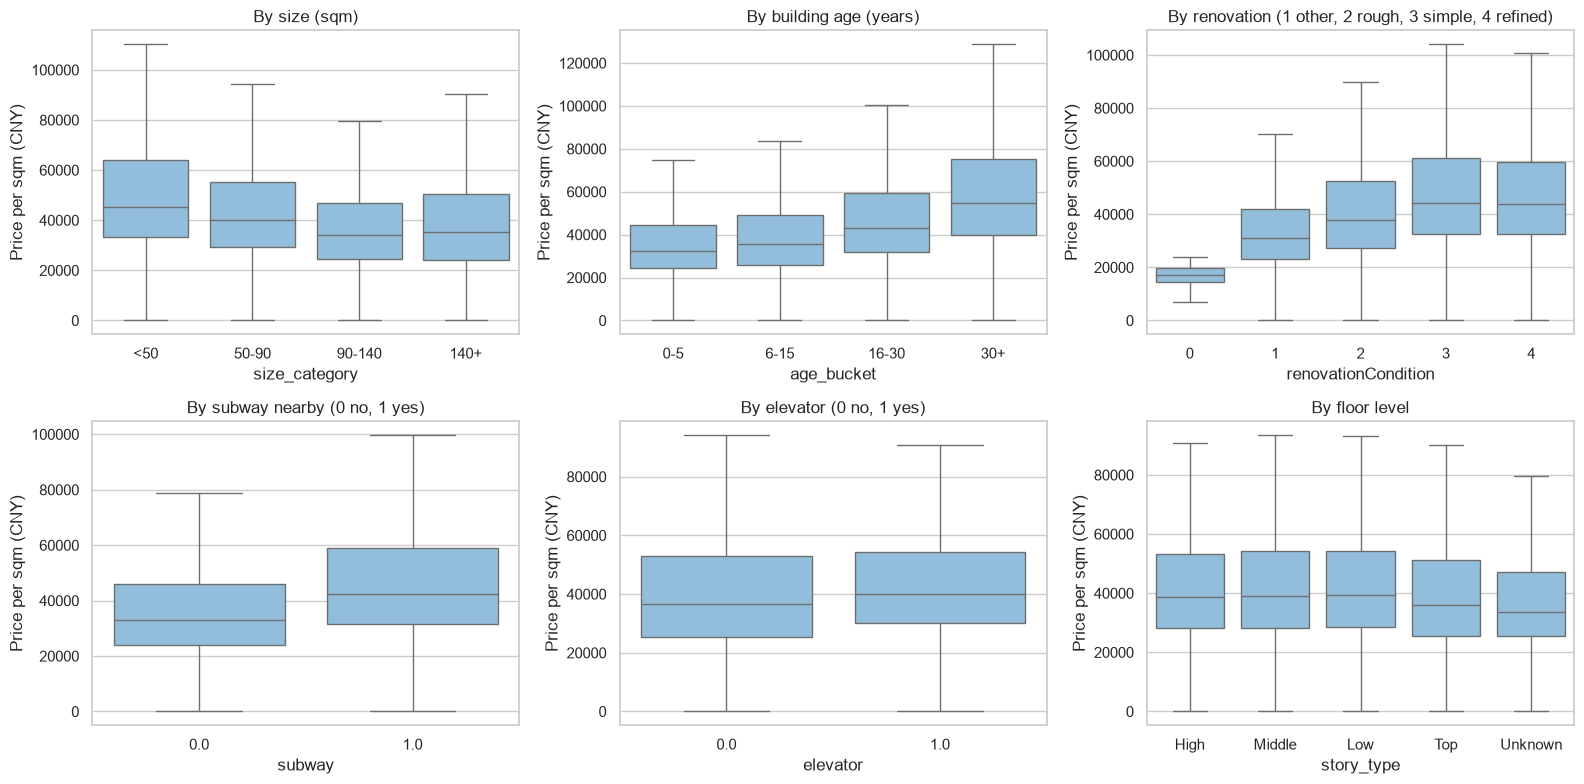

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

def price_by(col, ax, order=None, title=None):
    sns.boxplot(data=w, x=col, y="price", order=order, showfliers=False, ax=ax, color="#85c1e9")
    ax.set_title(title or f"Price per sqm by {col}")
    ax.set_ylabel("Price per sqm (CNY)")

price_by("size_category", axes[0, 0], ["<50", "50-90", "90-140", "140+"], "By size (sqm)")
price_by("age_bucket", axes[0, 1], ["0-5", "6-15", "16-30", "30+"], "By building age (years)")
price_by("renovationCondition", axes[0, 2], title="By renovation (1 other, 2 rough, 3 simple, 4 refined)")
price_by("subway", axes[1, 0], title="By subway nearby (0 no, 1 yes)")
price_by("elevator", axes[1, 1], title="By elevator (0 no, 1 yes)")
price_by("story_type", axes[1, 2], title="By floor level")
plt.tight_layout()
plt.show()

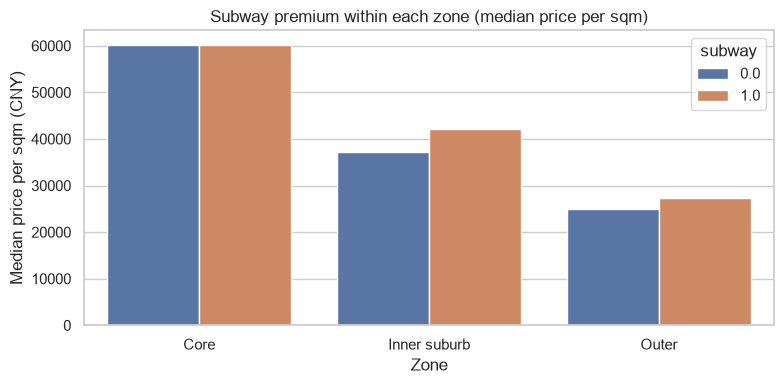

In [18]:
# Is the subway premium real, or just a location effect? Compare within each zone.
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=w, x="district_zone", y="price", hue="subway", order=ZONE_ORDER,
            estimator=np.median, errorbar=None, ax=ax)
ax.set_title("Subway premium within each zone (median price per sqm)")
ax.set_xlabel("Zone")
ax.set_ylabel("Median price per sqm (CNY)")
plt.tight_layout()
plt.show()

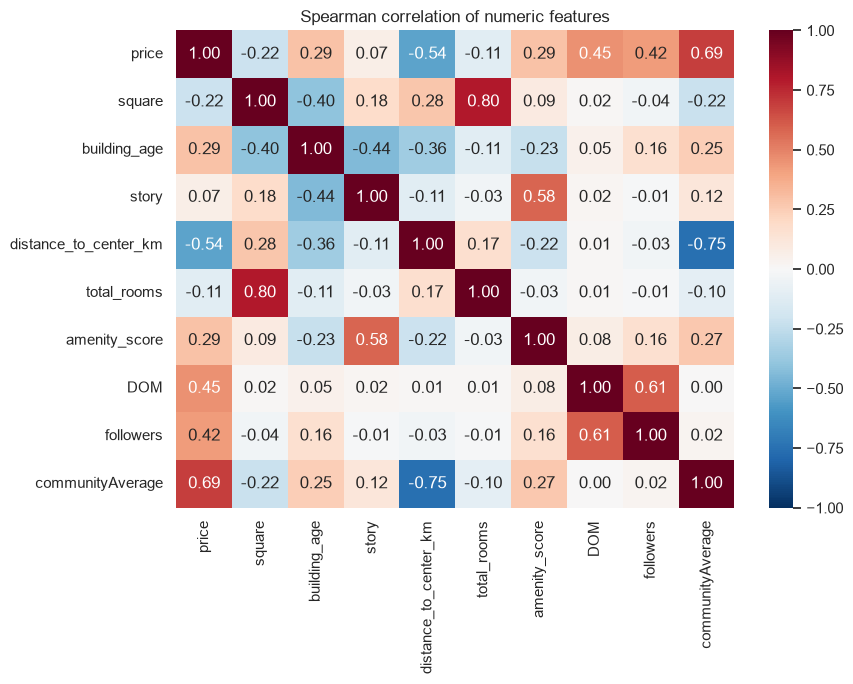

In [19]:
# Correlation of numeric features with price (Spearman handles skew and non-linear but monotonic links)
num_cols = [c for c in ["price", "square", "building_age", "story", "distance_to_center_km", "total_rooms",
                        "amenity_score", "DOM", "followers", "communityAverage"] if c in w.columns]
corr = w[num_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation of numeric features")
plt.tight_layout()
plt.show()

**Check `communityAverage`:** the appendix describes it as the *number of people living* in the community.
If its correlation with `price` is very high (say above 0.8), it is probably an average community **price**
instead. That would be a leakage risk in any price-prediction model and a good point to raise in Q&A.

## 5. How liquid is each segment?

EDA 2 used followers as a measure of interest. Days on market (DOM) measures how long a sale actually took,
so the two together describe demand and exit ease.

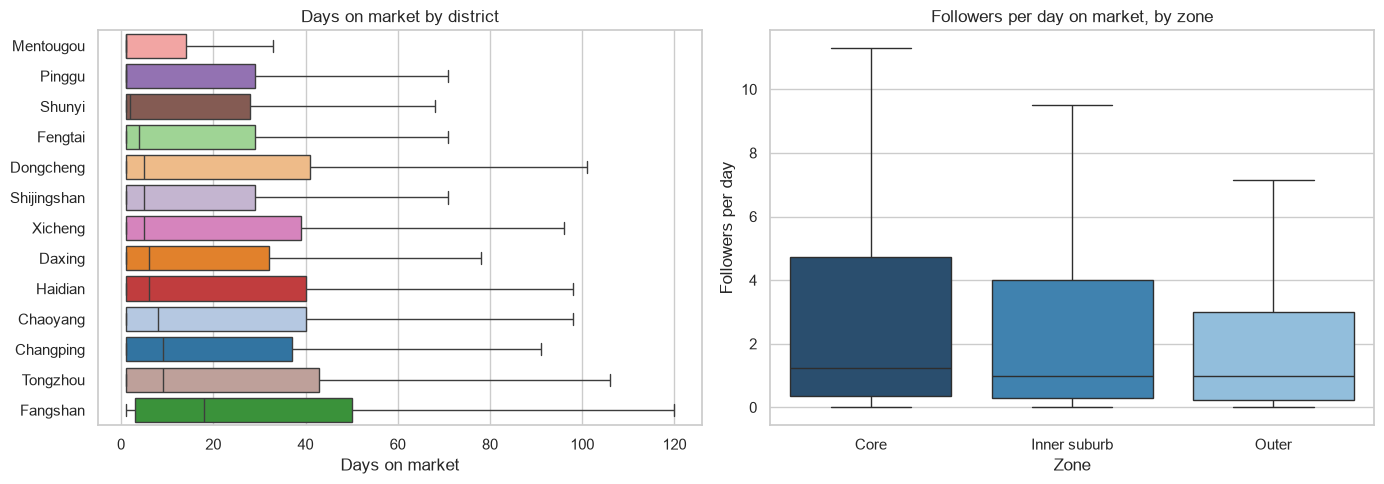

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

dom_order = w.groupby("district_name")["DOM"].median().sort_values().index
sns.boxplot(data=w, x="DOM", y="district_name", hue="district_name", order=dom_order,
            showfliers=False, palette=DISTRICT_COLORS, legend=False, ax=axes[0])
axes[0].set_title("Days on market by district")
axes[0].set_xlabel("Days on market")
axes[0].set_ylabel("")

sns.boxplot(data=w, x="district_zone", y="followers_per_day", hue="district_zone", order=ZONE_ORDER,
            showfliers=False, palette=ZONE_COLORS, legend=False, ax=axes[1])
axes[1].set_title("Followers per day on market, by zone")
axes[1].set_xlabel("Zone")
axes[1].set_ylabel("Followers per day")
plt.tight_layout()
plt.show()

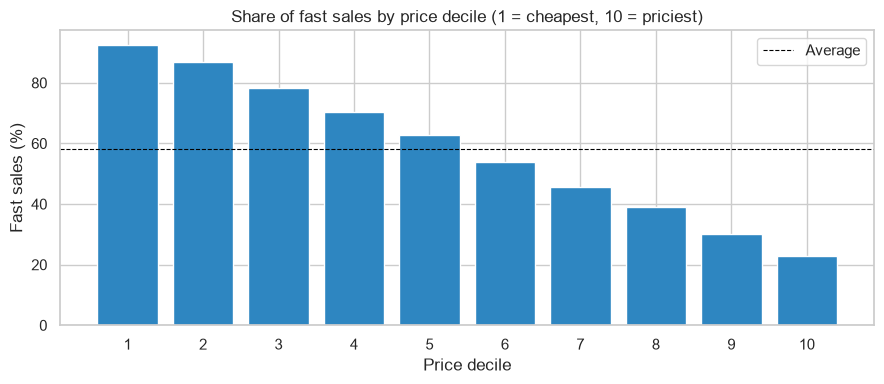

In [21]:
# Price vs speed of sale. Bin price into deciles and show the share of fast sales (DOM at or below the median).
w["price_decile"] = pd.qcut(w["price"], 10, labels=False, duplicates="drop") + 1
fast = w.groupby("price_decile")["is_fast_sale"].mean().mul(100)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(fast.index, fast.values, color="#2e86c1")
ax.axhline(fast.mean(), color="black", linestyle="--", linewidth=0.8, label="Average")
ax.set_xticks(range(1, 11))
ax.set_title("Share of fast sales by price decile (1 = cheapest, 10 = priciest)")
ax.set_xlabel("Price decile")
ax.set_ylabel("Fast sales (%)")
ax.legend()
plt.tight_layout()
plt.show()

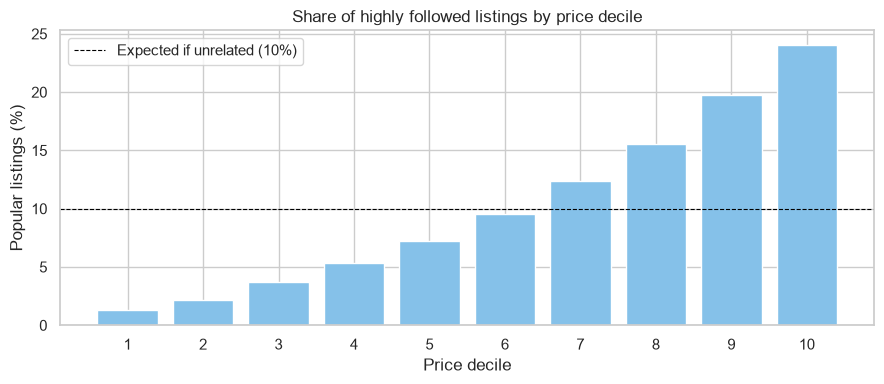

In [22]:
# Building on EDA 2's 'popular' flag (top 10% of followers): does popularity depend on price level?
w["popular"] = w["followers"] >= w["followers"].quantile(0.9)
pop = w.groupby("price_decile")["popular"].mean().mul(100)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(pop.index, pop.values, color="#85c1e9")
ax.axhline(10, color="black", linestyle="--", linewidth=0.8, label="Expected if unrelated (10%)")
ax.set_xticks(range(1, 11))
ax.set_title("Share of highly followed listings by price decile")
ax.set_xlabel("Price decile")
ax.set_ylabel("Popular listings (%)")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Which segments sell below their district norm?

`price_vs_district` is a property's price divided by the median for the same district and year.
Below 1 means it sold at a discount to its local market. Segments with a persistent discount might be
undervalued, or they might simply be worse (older, smaller, no elevator), so check both readings.

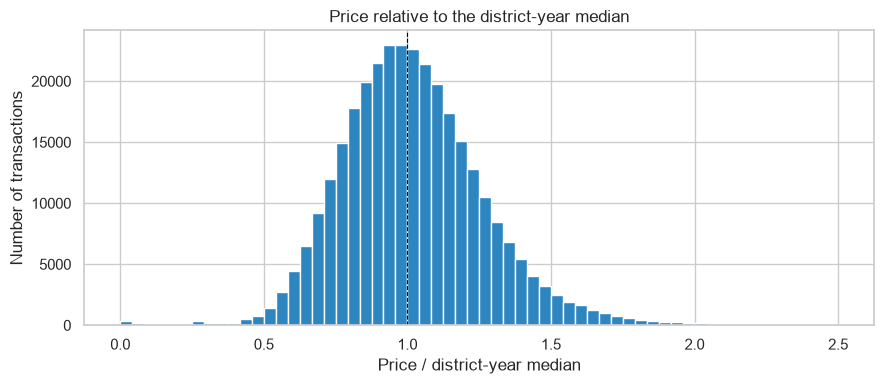

In [23]:
fig, ax = plt.subplots(figsize=(9, 4))
w["price_vs_district"].clip(0, 2.5).hist(bins=60, ax=ax, color="#2e86c1")
ax.axvline(1, color="black", linestyle="--", linewidth=0.8)
ax.set_title("Price relative to the district-year median")
ax.set_xlabel("Price / district-year median")
ax.set_ylabel("Number of transactions")
plt.tight_layout()
plt.show()

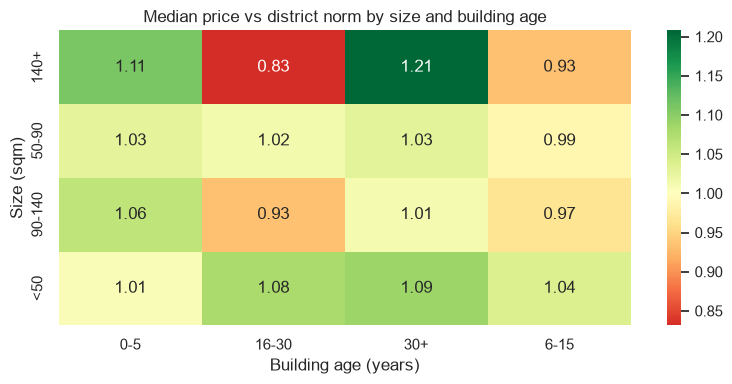

In [24]:
# Median relative price for each size x age segment (below 1 = discount to district norm)
seg = (w.groupby(["size_category", "age_bucket"], observed=True)["price_vs_district"].median()
         .unstack("age_bucket"))

fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(seg, annot=True, fmt=".2f", cmap="RdYlGn", center=1, ax=ax)
ax.set_title("Median price vs district norm by size and building age")
ax.set_xlabel("Building age (years)")
ax.set_ylabel("Size (sqm)")
plt.tight_layout()
plt.show()

## 7. Growth vs liquidity per district (quadrant preview)

A first draft of the strategy chart: districts that grow fast **and** sell fast are the safest targets,
fast growth with slow sales is higher risk, and so on. Bubble size is the number of transactions.

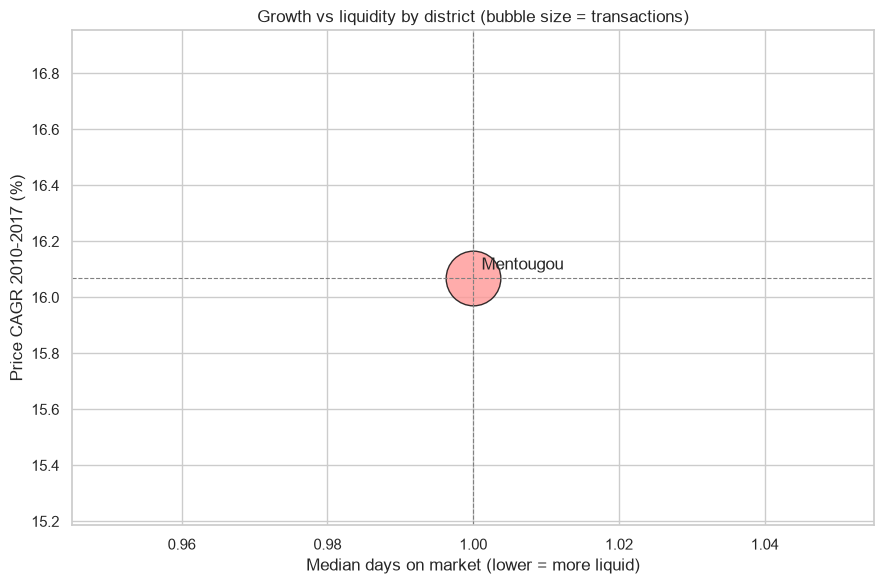

In [25]:
liq = w.groupby("district_name").agg(median_dom=("DOM", "median"), n=("price", "size"))
quad = growth[["cagr_pct"]].join(liq, how="inner")

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(quad["median_dom"], quad["cagr_pct"], s=quad["n"] / quad["n"].max() * 1500 + 50,
           c=[DISTRICT_COLORS[d] for d in quad.index], alpha=0.8, edgecolor="black")
for name, row in quad.iterrows():
    ax.annotate(name, (row["median_dom"], row["cagr_pct"]), xytext=(6, 6), textcoords="offset points")
ax.axvline(quad["median_dom"].median(), color="grey", linestyle="--", linewidth=0.8)
ax.axhline(quad["cagr_pct"].median(), color="grey", linestyle="--", linewidth=0.8)
ax.set_title("Growth vs liquidity by district (bubble size = transactions)")
ax.set_xlabel("Median days on market (lower = more liquid)")
ax.set_ylabel(f"Price CAGR {WINDOW[0]}-{WINDOW[1]} (%)")
plt.tight_layout()
plt.show()

## 8. Community-level table (input for clustering)

Districts are coarse. Communities (`Cid`) are the finer unit that the K-means clustering in the next notebook
can group into investor segments. Build and sanity-check the table here.

In [26]:
comm = (w.groupby("Cid")
          .agg(n=("price", "size"),
               median_price=("price", "median"),
               median_dom=("DOM", "median"),
               median_followers=("followers", "median"),
               median_dist_km=("distance_to_center_km", "median"),
               median_age=("building_age", "median"),
               district=("district_name", lambda s: s.mode().iat[0]))
          .query("n >= @MIN_N"))

# Per-community growth: median price in the first vs last two years of the window
early = w[w["trade_year"] <= WINDOW[0] + 1].groupby("Cid")["price"].median()
late = w[w["trade_year"] >= WINDOW[1] - 1].groupby("Cid")["price"].median()
span = (WINDOW[1] - 1) - (WINDOW[0] + 1)
comm["cagr_pct"] = (((late / early) ** (1 / span)) - 1).mul(100)

print(f"{len(comm):,} communities with at least {MIN_N} transactions; "
      f"{comm['cagr_pct'].notna().sum():,} have growth estimates")
comm.describe().round(1)

2,254 communities with at least 30 transactions; 1,507 have growth estimates


,n,median_price,median_dom,median_followers,median_dist_km,median_age,cagr_pct
count,2254.0,2254.0,2254.0,2254.0,2254.0,2253.0,1507.0
mean,133.1,42750.2,8.3,5.9,11.8,16.3,29.2
std,137.7,14983.5,8.5,5.3,7.4,8.6,73.7
min,30.0,11696.0,1.0,0.0,0.2,0.0,1.9
25%,51.0,31163.8,1.0,3.0,6.3,10.0,16.4
50%,86.0,40772.5,6.0,5.0,9.9,14.0,19.1
75%,162.0,51667.9,12.0,7.0,15.6,23.0,22.2
max,1525.0,105718.0,69.5,127.0,44.3,54.0,780.8


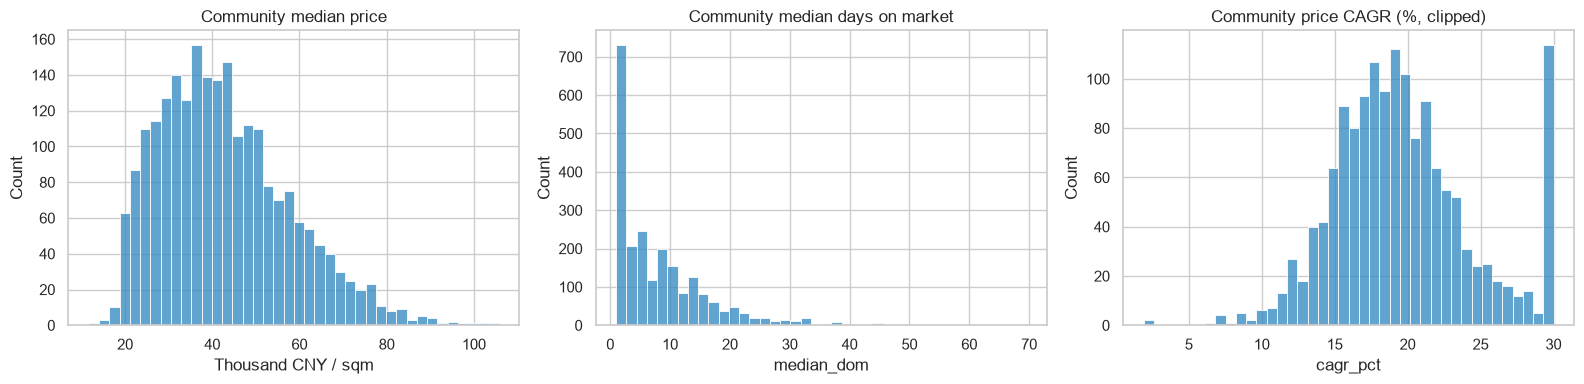

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(comm["median_price"] / 1000, bins=40, ax=axes[0], color="#2e86c1")
axes[0].set_title("Community median price")
axes[0].set_xlabel("Thousand CNY / sqm")
sns.histplot(comm["median_dom"], bins=40, ax=axes[1], color="#2e86c1")
axes[1].set_title("Community median days on market")
sns.histplot(comm["cagr_pct"].dropna().clip(-10, 30), bins=40, ax=axes[2], color="#2e86c1")
axes[2].set_title("Community price CAGR (%, clipped)")
plt.tight_layout()
plt.show()

## Findings to carry into the story

Fill this in after running the notebook. One line per section, written as a claim with a number.

- Where: 
- When: 
- Growth: 
- Drivers: 
- Liquidity: 
- Value: 
- Quadrant: 

## Next: EDA 4

K-means clustering of the community table, then a price model with feature importance.
Keep `price`, `price_per_sqm_calc`, `log_price_per_sqm`, `price_vs_district` and `district_median_price`
out of the model's inputs when the target is price, since they are the target or built from it.